# Логистическая регрессия и показатели ошибок классификации
![LogRegr.png](Assets/LogRegr.png)


# Цели обучения

- Описать логистическую регрессию и её отличия от линейной регрессии
- Определить метрики ошибок классификации и сценарии, в которых их можно использовать
- Применять расширение Intel® для Scikit-learn*, чтобы использовать вычислительные возможности аппаратного обеспечения



## Введение

Мы будем использовать базу данных [«Распознавание человеческой активности с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), которая была сформирована на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

In [32]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import precision_recall_fscore_support as score
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize

from sklearnex import patch_sklearn
patch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

Импортируйте данные и выполните следующие действия:

* Проанализируйте типы данных — столбцов много, поэтому целесообразно использовать подсчёт значений
* Определите, требуется ли масштабирование значений с плавающей запятой
* Определите структуру каждого вида деятельности
* Кодируйте название вида деятельности в виде целого числа

1. В датасете 561 столбец имеет тип float64 (числа с плавающей запятой) и только 1 столбец имеет тип str (строка). Этим единственным строковым столбцом является
 целевая переменная activity (вид деятельности).
2. Минимальное значение для всех признаков равно -1.0, а максимальное — 1.0. Это означает, что все признаки уже нормализованы и приведены к единому масштабу (от -1 до 1), 
поэтому дополнительное масштабирование (например, StandardScaler или MinMaxScaler) не требуется.
3. Датасет содержит 6 видов деятельности, и они относительно сбалансированы (количество записей по каждому классу находится в диапазоне от 1406 до 1944):

    LAYING: 1944

    STANDING: 1906

    SITTING: 1777

    WALKING: 1722

    WALKING_UPSTAIRS: 1544

    WALKING_DOWNSTAIRS: 1406
4. Для проверки выведены 5 случайных значений из нового столбца, которые теперь представлены целыми числами (например, 5, 3, 0).

In [31]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')

Все столбцы данных содержат числа типа float, за исключением метки активности.

In [ ]:
data.dtypes.value_counts()

In [ ]:
data.dtypes.tail()

Все данные приведены к шкале от -1 (минимум) до 1,0 (максимум).

In [ ]:
data.iloc[:, :-1].min().value_counts()

In [ ]:
data.iloc[:, :-1].max().value_counts()

Проанализируйте структуру мероприятий — они относительно сбалансированы.

In [ ]:
data.Activity.value_counts()

Классификаторы Scikit-learn не принимают разреженные матрицы в качестве столбца для прогнозирования. Поэтому необходимо либо использовать `LabelEncoder` для преобразования меток активности в целые числа, либо, если используется `DictVectorizer`, преобразовать результирующую матрицу в неразреженный массив.
Используйте `LabelEncoder` для преобразования столбца «Activity» с помощью `fit_transform` и просмотрите 5 случайных значений.

In [ ]:
le = LabelEncoder()
data['Activity'] = le.fit_transform(data.Activity)
data['Activity'].sample(5)

## Вопрос 2

* Рассчитайте коэффициенты корреляции между зависимыми переменными.
* Постройте гистограмму значений коэффициентов корреляции.
* Определите, какие из них наиболее сильно коррелируют (положительно или отрицательно).

1. Наиболее сильная положительная корреляция (1.0)


    fBodyBodyGyroJerkMag-mean() и fBodyBodyGyroJerkMag-sma() (1.000000)

    tBodyAccMag-sma() и tGravityAccMag-sma() (1.000000)

    tBodyAccJerkMag-mean() и tBodyAccJerkMag-sma() (1.000000)

    tGravityAccMag-mean() и tGravityAccMag-sma() (1.000000)

    tBodyAccMag-energy() и tGravityAccMag-energy() (1.000000)

2. Наиболее сильная отрицательная корреляция (близкая к -1.0)

    tGravityAcc-arCoeff()_Z_1 и tGravityAcc-arCoeff()_Z_2 (-0.995195)

    tGravityAcc-mean()_Z и angle(Z,gravityMean) (-0.994764)

    tGravityAcc-arCoeff()_Z_2 и tGravityAcc-arCoeff()_Z_3 (-0.994628)

    tGravityAcc-arCoeff()_Z_3 и tGravityAcc-arCoeff()_Z_4 (-0.994267)

    tGravityAcc-mean()_Y и angle(Y,gravityMean) (-0.993425)

In [ ]:
import numpy as np
import pandas as pd

# Calculate the correlation values
feature_cols = data.columns[:-1]
corr_values = data[feature_cols].corr()

# Simplify by emptying all the data below the diagonal
tril_index = np.tril_indices_from(corr_values)

# Make the unused values NaNs
for coord in zip(*tril_index):
    corr_values.iloc[coord[0], coord[1]] = np.nan # <--- ИСПРАВЛЕНО ЗДЕСЬ

# Stack the data and convert to a data frame
corr_values = (corr_values
               .stack()
               .to_frame()
               .reset_index()
               .rename(columns={'level_0':'feature1',
                                'level_1':'feature2',
                                0:'correlation'}))

# Get the absolute values for sorting
corr_values['abs_correlation'] = corr_values.correlation.abs() 

Гистограмма корреляций по абсолютным значениям.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [ ]:
sns.set_context('talk')
sns.set_style('white')
sns.set_palette('dark')

ax = corr_values.abs_correlation.hist(bins=50)

ax.set(xlabel='Absolute Correlation', ylabel='Frequency');

In [30]:
# The most highly correlated values
corr_values.sort_values('correlation', ascending=False).query('abs_correlation>0.8')

,feature1,feature2,correlation,abs_correlation
304047,fBodyBodyGyroJerkMag-mean(),fBodyBodyGyroJerkMag-sma(),1.000000,1.000000
115223,tBodyAccMag-sma(),tGravityAccMag-sma(),1.000000,1.000000
127017,tBodyAccJerkMag-mean(),tBodyAccJerkMag-sma(),1.000000,1.000000
119711,tGravityAccMag-mean(),tGravityAccMag-sma(),1.000000,1.000000
115785,tBodyAccMag-energy(),tGravityAccMag-energy(),1.000000,1.000000
...,...,...,...,...
23560,tGravityAcc-mean()-Y,"angle(Y,gravityMean)",-0.993425,0.993425
42151,"tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4",-0.994267,0.994267
41589,"tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3",-0.994628,0.994628
24122,tGravityAcc-mean()-Z,"angle(Z,gravityMean)",-0.994764,0.994764


## Вопрос 3

* Разделите данные на обучающий и тестовый наборы. Это можно сделать любым способом, но рекомендуется использовать метод `StratifiedShuffleSplit` из библиотеки Scikit-learn, чтобы сохранить одинаковое соотношение классов предикторов.
* Независимо от метода, использованного для разделения данных, сравните соотношение классов в обучающем и тестовом наборах.


In [ ]:
Соотношение классов в обучающей (y_train, ячейка 19) и тестовой (y_test, ячейка 20) выборках практически идентично.

In [33]:
# Get the split indexes
strat_shuf_split = StratifiedShuffleSplit(n_splits=1,
                                          test_size=0.3,
                                          random_state=42)

train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data.Activity))

# Create the dataframes
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'Activity']

X_test  = data.loc[test_idx, feature_cols]
y_test  = data.loc[test_idx, 'Activity']

In [28]:
y_train.value_counts(normalize=True)

Activity
0    0.188792
2    0.185046
1    0.172562
3    0.167152
5    0.149951
4    0.136496
Name: proportion, dtype: float64

In [29]:
y_test.value_counts(normalize=True)

Activity
0    0.188673
2    0.185113
1    0.172492
3    0.167314
5    0.149838
4    0.136570
Name: proportion, dtype: float64

## Вопрос 4

* Постройте модель логистической регрессии без какой-либо регуляризации с использованием всех признаков. Обязательно ознакомьтесь с документацией по построению многоклассовых моделей, чтобы понять, как интерпретировать выведенные коэффициенты. Сохраните модель.
* Используя перекрестную валидацию для определения гиперпараметров, постройте модели с L1- и L2-регуляризацией. Сохраните также каждую из этих моделей. Обратите внимание на ограничения, связанные с многоклассовыми моделями, решателями и видами регуляризации. Построение регуляризованных моделей, в частности модели с L1-регуляризацией, вероятно, займет некоторое время.

In [34]:
# Standard logistic regression
lr = LogisticRegression(C=.001, max_iter=295).fit(X_train, y_train)

In [35]:
# L1 regularized logistic regression
#lr_l1 = LogisticRegressionCV(Cs=10, cv=4, penalty='l1', solver='liblinear').fit(X_train, y_train)

from sklearn.linear_model import LogisticRegressionCV
from sklearn.multiclass import OneVsRestClassifier

# Create the base estimator with liblinear
base_lr = LogisticRegressionCV(Cs=10, cv=4, penalty='l1', solver='liblinear')

# Wrap it to handle multiclass explicitly via One-vs-Rest
lr_l1 = OneVsRestClassifier(base_lr).fit(X_train, y_train)

C:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
C:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
C:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_

In [36]:
# L2 regularized logistic regression
lr_l2 = LogisticRegressionCV(Cs=1, cv=4, penalty='l2').fit(X_train, y_train)

C:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
C:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
C:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_

## Вопрос 5

Сравните величины коэффициентов для каждой из моделей. Если использовалась подстановка «один против остальных», каждый набор коэффициентов можно отобразить на графике отдельно.

In [ ]:
1. для l1 столбцы будут "рваными" (много пустот из-за нулей), а для l2 — более плотными, но с низкой амплитудой.

In [39]:
import numpy as np
import pandas as pd

# Combine all the coefficients into a dataframe
coefficients = list()

coeff_labels = ['lr', 'l1', 'l2']
coeff_models = [lr, lr_l1, lr_l2]

for lab, mod in zip(coeff_labels, coeff_models):
    # Проверяем, обернута ли модель в OneVsRestClassifier
    if hasattr(mod, 'estimators_'):
        # Собираем коэффициенты из каждой внутренней модели и склеиваем их
        # (в OvR каждая модель выдает массив формы (1, n_features), 
        # поэтому используем vstack или concatenate)
        coeffs = np.vstack([est.coef_ for est in mod.estimators_])
    else:
        # Если модель обычная (например, мультиномиальная), берем coef_ напрямую
        coeffs = mod.coef_
        
    coeff_label = pd.MultiIndex(levels=[[lab], [0,1,2,3,4,5]],
                                codes=[[0,0,0,0,0,0], [0,1,2,3,4,5]])
    
    # coeffs.T транспонирует матрицу, чтобы признаки стали строками, а классы - столбцами
    coefficients.append(pd.DataFrame(coeffs.T, columns=coeff_label))

coefficients = pd.concat(coefficients, axis=1)

# Выводим 10 случайных строк (признаков) для просмотра
coefficients.sample(10)

lr                                                          l1  \
            0         1         2         3         4         5         0   
343 -0.001195 -0.001673 -0.002064  0.006425  0.008541 -0.010034 -0.025176   
256 -0.009434 -0.014011 -0.013476  0.032324  0.001078  0.003518  0.000000   
216 -0.013404 -0.021687 -0.032980 -0.041950  0.088580  0.021441  0.000000   
428 -0.015105 -0.015902 -0.025328  0.009580 -0.014197  0.060952  0.000000   
177 -0.001787 -0.002418 -0.002496  0.011179  0.006885 -0.011363  0.019353   
456  0.004883  0.024068 -0.037581  0.001903 -0.066370  0.073097  0.065839   
284 -0.014729 -0.023577 -0.026705 -0.001590  0.049739  0.016861  0.000000   
409 -0.004922 -0.006250 -0.008094  0.003476  0.002477  0.013312 -0.047911   
130 -0.009267 -0.011648 -0.011885  0.027124  0.000505  0.005171  0.000000   
285 -0.016289 -0.022072 -0.025332  0.030946  0.029365  0.003382  0.000000   

                                                             l2            \
            1         2         3         4         5         0         1   
343  0.668574  0.234265  0.000000  0.026016  0.174336 -0.000916 -0.000986   
256 -0.218949  0.000000  0.446785 -0.097312  0.000000 -0.005474 -0.006126   
216 -2.061366  0.000000 -2.010578  0.000000  0.000000 -0.010369 -0.012202   
428  0.000000  0.000000  0.000000 -0.437799  0.966229 -0.008628 -0.008821   
177  0.387495  0.004635  0.000000  0.000403  0.000000 -0.001340 -0.001446   
456 -0.462110  0.000000  0.000000 -1.320463  1.849545  0.003987  0.003237   
284 -0.000487  0.000000 -0.441650  1.576040  0.527374 -0.009173 -0.010859   
409  0.000000  0.000906  0.339592  0.328212 -0.234294 -0.002848 -0.003026   
130  0.000000  0.000000  0.919041 -0.470986 -0.390061 -0.005730 -0.006150   
285 -0.916499  0.000000  0.000000 -0.147975  0.823900 -0.009622 -0.010544   

                                             
            2         3         4         5  
343 -0.001126  0.001671  0.003349 -0.001992  
256 -0.006429  0.009284  0.005772  0.002973  
216 -0.014515  0.000005  0.026906  0.010177  
428 -0.010477  0.006288  0.003060  0.018577  
177 -0.001592  0.003902  0.003238 -0.002761  
456 -0.007443 -0.002581 -0.014894  0.017694  
284 -0.012040  0.006887  0.019526  0.005659  
409 -0.003547  0.001081  0.002739  0.005601  
130 -0.006349  0.008689  0.004645  0.004895  
285 -0.011561  0.014053  0.014329  0.003345

Подготовьте шесть отдельных графиков для каждого из многоклассовых коэффициентов.

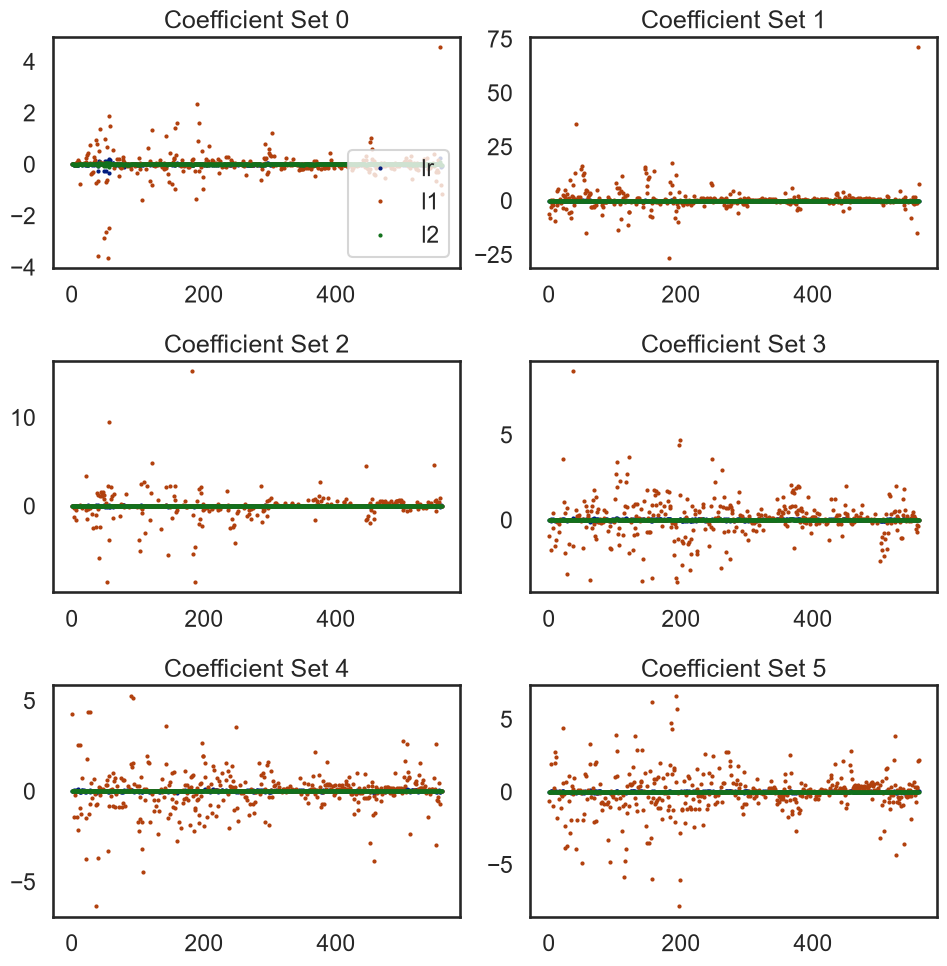

In [40]:
fig, axList = plt.subplots(nrows=3, ncols=2)
axList = axList.flatten()
fig.set_size_inches(10,10)

for ax in enumerate(axList):
    loc = ax[0]
    ax = ax[1]

    data = coefficients.xs(loc, level=1, axis=1)
    data.plot(marker='o', ls='', ms=2.0, ax=ax, legend=False)

    if ax is axList[0]:
        ax.legend(loc=4)

    ax.set(title='Coefficient Set '+str(loc))

plt.tight_layout()

## Вопрос 6

* Определите и сохраните класс для каждой модели.
* Также сохраните вероятность для предсказанного класса для каждой модели.

In [41]:
# Predict the class and the probability for each
y_pred = list()
y_prob = list()

coeff_labels = ['lr', 'l1', 'l2']
coeff_models = [lr, lr_l1, lr_l2]

for lab,mod in zip(coeff_labels, coeff_models):
    y_pred.append(pd.Series(mod.predict(X_test), name=lab))
    y_prob.append(pd.Series(mod.predict_proba(X_test).max(axis=1), name=lab))

y_pred = pd.concat(y_pred, axis=1)
y_prob = pd.concat(y_prob, axis=1)

y_pred.head()

,lr,l1,l2
0,WALKING,WALKING,WALKING
1,WALKING_UPSTAIRS,WALKING_UPSTAIRS,WALKING_UPSTAIRS
2,WALKING,WALKING,WALKING
3,SITTING,SITTING,SITTING
4,LAYING,LAYING,LAYING


In [42]:
y_prob.head()

,lr,l1,l2
0,0.733081,0.998909,0.344248
1,0.510260,0.999548,0.313613
2,0.561791,0.998971,0.305936
3,0.537575,0.999169,0.333385
4,0.822256,1.000000,0.486744


## Вопрос 7

Для каждой модели рассчитайте следующие показатели ошибок:

* точность
* прецизионность
* полнота
* F-показатель
* матрица путаницы

Определите, как объединить показатели для нескольких классов в одно значение для каждой модели.

In [43]:
metrics = list()
cm = dict()

for lab in coeff_labels:

    # Preciision, recall, f-score from the multi-class support function
    precision, recall, fscore, _ = score(y_test, y_pred[lab], average='weighted')

    # The usual way to calculate accuracy
    accuracy = accuracy_score(y_test, y_pred[lab])

    # ROC-AUC scores can be calculated by binarizing the data
    auc = roc_auc_score(label_binarize(y_test, classes=[0,1,2,3,4,5]),
              label_binarize(y_pred[lab], classes=[0,1,2,3,4,5]),
              average='weighted')

    # Last, the confusion matrix
    cm[lab] = confusion_matrix(y_test, y_pred[lab])

    metrics.append(pd.Series({'precision':precision, 'recall':recall,
                              'fscore':fscore, 'accuracy':accuracy,
                              'auc':auc},
                             name=lab))

metrics = pd.concat(metrics, axis=1)

In [44]:
metrics

,lr,l1,l2
precision,0.911089,0.982850,0.866025
recall,0.910356,0.982848,0.851780
fscore,0.909827,0.982847,0.844951
accuracy,0.910356,0.982848,0.851780
auc,0.000000,0.000000,0.000000


## Вопрос 8

Отобразите или постройте матрицу путаницы для каждой модели.

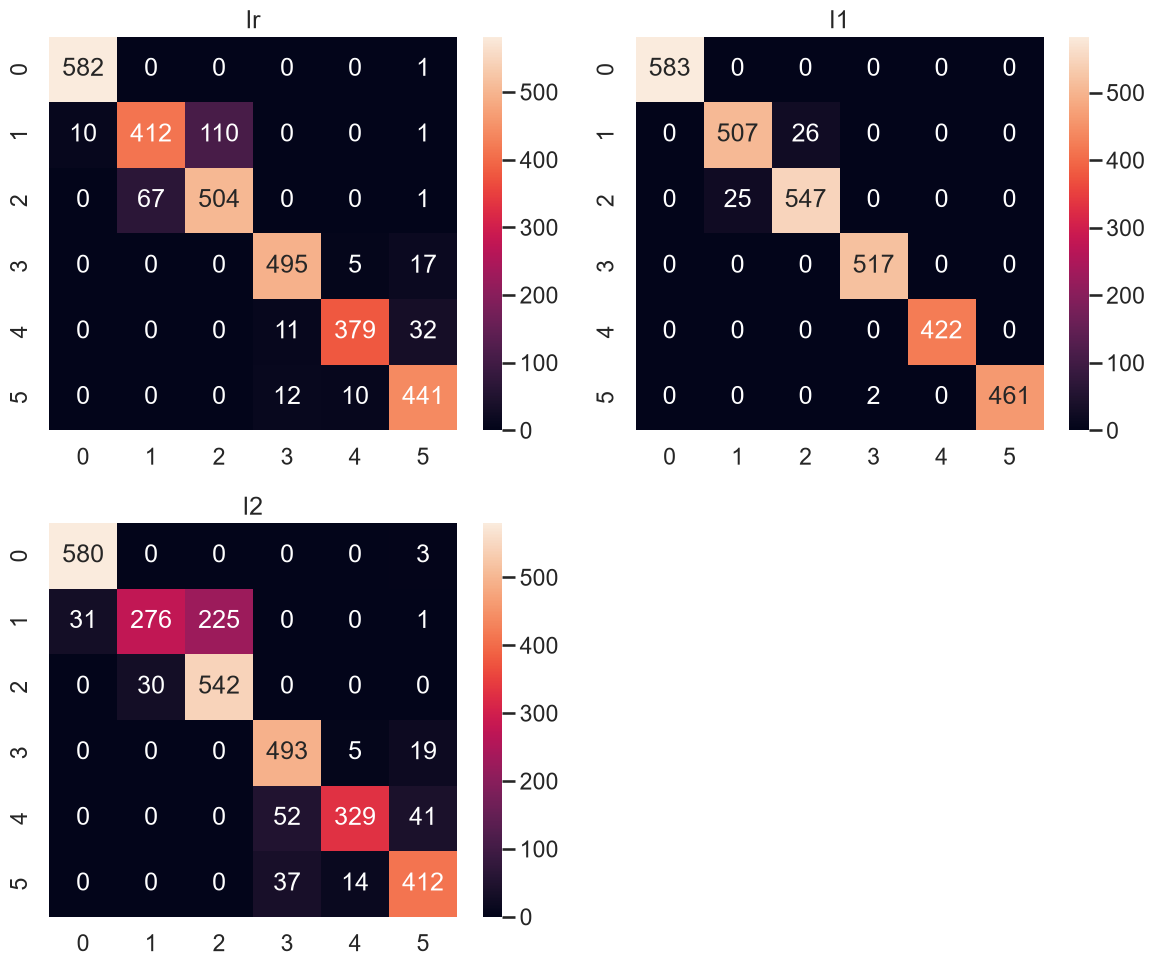

In [45]:
fig, axList = plt.subplots(nrows=2, ncols=2)
axList = axList.flatten()
fig.set_size_inches(12, 10)

axList[-1].axis('off')

for ax,lab in zip(axList[:-1], coeff_labels):
    sns.heatmap(cm[lab], ax=ax, annot=True, fmt='d');
    ax.set(title=lab);

plt.tight_layout()